In [24]:

# AYARLAR VE VERİ YÜKLEME
import os
import random

random.seed(42)    

veri_setleri = {
    "veri_seti_1": "../data/veri_seti_1",   # klasör sınıflandırmalı (bird / drone klasörleri)
    "veri_seti_2": "../data/veri_seti_2",   # etiket dosyaları (.txt) ayrı klasörde
    "veri_seti_3": "../data/veri_seti_3",   # YOLOv8 formatı (train / valid / test)
}
resim_uzantilari = (".png", ".jpg", ".jpeg")

resimler = {}    # her veri setinin resim yollarının listesi
for isim, yol in veri_setleri.items():
    resimler[isim] = []
    if not os.path.exists(yol):
        print("UYARI: klasör bulunamadı", yol)
        continue
    for root, dirs, files in os.walk(yol):
        for file in files:
            if file.lower().endswith(resim_uzantilari):
                resimler[isim].append(os.path.join(root, file))
    print(isim, "->", len(resimler[isim]), "resim")

print("\n SINIF ADI DOSYALARI ")
# SINIF ADI DOSYALARINI GÖSTER
for isim, yol in veri_setleri.items():
    for root, dirs, files in os.walk(yol):
        for file in files:
            if file.lower() in ("classes.txt", "data.yaml", "data.yml"):
                print(f" {isim} / {file} ")
                dosya = open(os.path.join(root, file), encoding="utf-8")
                print(dosya.read())
                dosya.close()

print("\n ETİKET DOSYALARI KONTROLÜ ")
# ETİKET DOSYALARINI BUL
etiket_yolu = {}    # resim yolu, etiket (.txt) dosyasının yolu (yoksa None)

for isim in veri_setleri:
    bulunan = 0
    for resim in resimler[isim]:
        ayni_klasor = os.path.splitext(resim)[0] + ".txt"                       
        labels_klasoru = ayni_klasor.replace(os.sep + "images" + os.sep, os.sep + "labels" + os.sep)
        
        # Veri Seti 2'nin klasör yapısı için özel düzeltme:
        ozel_birds = ayni_klasor.replace("images_birds", "labels_birds")
        ozel_drones = ayni_klasor.replace("images_drones", "labels_drones")

        if os.path.exists(ayni_klasor):
            etiket_yolu[resim] = ayni_klasor
            bulunan += 1
        elif os.path.exists(labels_klasoru):
            etiket_yolu[resim] = labels_klasoru
            bulunan += 1
        elif os.path.exists(ozel_birds):
            etiket_yolu[resim] = ozel_birds
            bulunan += 1
        elif os.path.exists(ozel_drones):
            etiket_yolu[resim] = ozel_drones
            bulunan += 1
        else:
            etiket_yolu[resim] = None
            
    print(isim, "->", len(resimler[isim]), "resimden", bulunan, "tanesinin etiket dosyası bulundu")
def kutulari_oku(etiket_dosyasi):
    """Etiket dosyasını okur. Her nesne için (sinif_no, x, y, genislik, yukseklik) listesi döndürür."""
    kutular = []
    dosya = open(etiket_dosyasi, encoding="utf-8")
    satirlar = dosya.read().splitlines()
    dosya.close()
    for satir in satirlar:
        parcalar = satir.split()
        if len(parcalar) == 5:                      # normal kutu etiketi
            kutular.append((int(float(parcalar[0])), float(parcalar[1]), float(parcalar[2]),
                            float(parcalar[3]), float(parcalar[4])))
        elif len(parcalar) > 5:                     # çokgen etiketi: köşe noktalarından kutu hesapla
            sayilar = parcalar[1:]
            xler = []
            yler = []
            for i in range(0, len(sayilar) - 1, 2):
                xler.append(float(sayilar[i]))
                yler.append(float(sayilar[i + 1]))
            kutular.append((int(float(parcalar[0])), (min(xler) + max(xler)) / 2, (min(yler) + max(yler)) / 2,
                            max(xler) - min(xler), max(yler) - min(yler)))
    return kutular

veri_seti_1 -> 4104 resim
veri_seti_2 -> 17936 resim
veri_seti_3 -> 6029 resim

 SINIF ADI DOSYALARI 
 veri_seti_3 / data.yaml 
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 2
names: ['Bird', 'Drone']

roboflow:
  workspace: drone-vs-bird-4idpt
  project: drone-vs-bird-v3
  version: 3
  license: CC BY 4.0
  url: https://universe.roboflow.com/drone-vs-bird-4idpt/drone-vs-bird-v3/dataset/3

 ETİKET DOSYALARI KONTROLÜ 
veri_seti_1 -> 4104 resimden 0 tanesinin etiket dosyası bulundu
veri_seti_2 -> 17936 resimden 17936 tanesinin etiket dosyası bulundu
veri_seti_3 -> 6029 resimden 6029 tanesinin etiket dosyası bulundu


In [28]:
# VERİ SETİ GENEL ÖZELLİKLERİ
from PIL import Image

# Etiket numarası -> sınıf adı (0: Bird, 1: Drone olarak doğrulandı)
sinif_adlari = {
    "veri_seti_2": {0: "bird", 1: "drone"},
    "veri_seti_3": {0: "bird", 1: "drone"},
}

sonuc = {}              # raporda ve grafiklerde kullanacağım değerler
sinif_resimleri = {}    # veri seti -> {"bird": [yollar], "drone": [yollar]}
bozuk_listesi = []      # bozuk dosyaların yolları

print(" VERİ SETİ GENEL ÖZELLİKLERİ")

for isim, yol in veri_setleri.items():
    liste = resimler[isim]
    if len(liste) == 0:
        continue

    kus_sayisi = 0
    drone_sayisi = 0
    sinifsiz_sayisi = 0
    kutu_sayisi = 0
    egitim_sayisi = 0
    dogrulama_sayisi = 0
    test_sayisi = 0
    etiketli = 0
    etiketsiz = 0
    bozuk = 0
    formatlar = []
    min_gen = 100000
    max_gen = 0
    min_yuk = 100000
    max_yuk = 0
    sinif_resimleri[isim] = {"bird": [], "drone": []}

    for resim in liste:
        goreli = os.path.dirname(resim)[len(yol):].lower()

        # Format
        uzanti = os.path.splitext(resim)[1].lower().replace(".", "")
        if uzanti not in formatlar:
            formatlar.append(uzanti)

        # Eğitim / doğrulama / test
        if "train" in goreli:
            egitim_sayisi += 1
        elif "valid" in goreli or "val" in goreli:
            dogrulama_sayisi += 1
        elif "test" in goreli:
            test_sayisi += 1

        # Sınıf: önce klasör adından
        sinif = None
        if "bird" in goreli:
            sinif = "bird"
        elif "drone" in goreli:
            sinif = "drone"

        # Etiket dosyası
        if etiket_yolu[resim] is not None:
            kutular = kutulari_oku(etiket_yolu[resim])
            if len(kutular) > 0:
                etiketli += 1
                kutu_sayisi += len(kutular)
                if sinif is None:                              
                    sinif_no = kutular[0][0]
                    if isim in sinif_adlari and sinif_no in sinif_adlari[isim]:
                        sinif = sinif_adlari[isim][sinif_no]
            else:
                etiketsiz += 1                                 
        else:
            etiketsiz += 1                                     

        # Sınıf sayaçları
        if sinif == "bird":
            kus_sayisi += 1
            sinif_resimleri[isim]["bird"].append(resim)
        elif sinif == "drone":
            drone_sayisi += 1
            sinif_resimleri[isim]["drone"].append(resim)
        else:
            sinifsiz_sayisi += 1

        # Boyut ve bozuk dosya kontrolü
        try:
            with Image.open(resim) as img:
                gen = img.width
                yuk = img.height
                img.verify()                                   
            if gen < min_gen: min_gen = gen
            if gen > max_gen: max_gen = gen
            if yuk < min_yuk: min_yuk = yuk
            if yuk > max_yuk: max_yuk = yuk
        except Exception:
            bozuk += 1
            bozuk_listesi.append(resim)

    sonuc[isim] = {"toplam": len(liste), "bird": kus_sayisi, "drone": drone_sayisi, "sinifsiz": sinifsiz_sayisi,
                   "egitim": egitim_sayisi, "dogrulama": dogrulama_sayisi, "test": test_sayisi,
                   "bozuk": bozuk, "etiketli": etiketli, "etiketsiz": etiketsiz, "kutu": kutu_sayisi}

    print(f"\n {isim} \n")
    print(f"Toplam Veri Sayısı: {len(liste)}")
    print(f"Veri Formatı: {', '.join(formatlar)}")
    print(f"Veri Boyutu: genişlik {min_gen}–{max_gen}, yükseklik {min_yuk}–{max_yuk}")
    if egitim_sayisi > 0 or dogrulama_sayisi > 0 or test_sayisi > 0:
        print(f"Dağılım: Eğitim: {egitim_sayisi} | Doğrulama: {dogrulama_sayisi} | Test: {test_sayisi}")
    else:
        print("Dağılım: Tek klasör (Eğitim/Doğrulama/Test ayrımı yapılmamış)")
    print(f"Sınıf Sayısı: {int(kus_sayisi > 0) + int(drone_sayisi > 0)}")
    print(f"Sınıflara Göre Veri Dağılımı: Kuş (Bird): {kus_sayisi} | İHA (Drone): {drone_sayisi} | Belirlenemeyen: {sinifsiz_sayisi}")
    print(f"Eksik/Bozuk Veri: {bozuk} bozuk görsel, {etiketsiz} resimde etiket yok veya boş")
    if etiketli == 0:
        print("Etiket Durumu: Etiket dosyası yok (sınıf klasör adından alınıyor)")
    else:
        print(f"Etiket Durumu: {etiketli} resimde etiket var, toplam {kutu_sayisi} nesne (kutu)")

 VERİ SETİ GENEL ÖZELLİKLERİ

 veri_seti_1 

Toplam Veri Sayısı: 4104
Veri Formatı: jpg, jpeg, png
Veri Boyutu: genişlik 163–4633, yükseklik 114–3089
Dağılım: Tek klasör (Eğitim/Doğrulama/Test ayrımı yapılmamış)
Sınıf Sayısı: 2
Sınıflara Göre Veri Dağılımı: Kuş (Bird): 1605 | İHA (Drone): 2499 | Belirlenemeyen: 0
Eksik/Bozuk Veri: 0 bozuk görsel, 4104 resimde etiket yok veya boş
Etiket Durumu: Etiket dosyası yok (sınıf klasör adından alınıyor)

 veri_seti_2 

Toplam Veri Sayısı: 17936
Veri Formatı: png
Veri Boyutu: genişlik 640–640, yükseklik 640–640
Dağılım: Tek klasör (Eğitim/Doğrulama/Test ayrımı yapılmamış)
Sınıf Sayısı: 2
Sınıflara Göre Veri Dağılımı: Kuş (Bird): 8936 | İHA (Drone): 9000 | Belirlenemeyen: 0
Eksik/Bozuk Veri: 0 bozuk görsel, 0 resimde etiket yok veya boş
Etiket Durumu: 17936 resimde etiket var, toplam 20664 nesne (kutu)

 veri_seti_3 

Toplam Veri Sayısı: 6029
Veri Formatı: jpg
Veri Boyutu: genişlik 640–640, yükseklik 640–640
Dağılım: Eğitim: 5397 | Doğrulama: 379 

In [29]:
# KONTROL 1: VERİ ÇOĞALTMA VE BENZER DOSYA ADLARI
print(" VERİ KALİTESİ KONTROLLERİ")

artirma_izleri = ["_r90", "_r180", "_r270", "_darker", "_brighter", "_blur", "_noise"] # veri artırma yöntemleri uygulananları bulmak sızıntıyı engellemek için 

for isim in veri_setleri:
    izli = 0
    ucak_adli = 0
    ucak_ornekleri = []
    for resim in resimler[isim]:
        dosya_adi = os.path.basename(resim).lower()
        for iz in artirma_izleri:
            if iz in dosya_adi:
                izli += 1
                break
        if "plane" in dosya_adi:
            ucak_adli += 1
            if len(ucak_ornekleri) < 3:
                ucak_ornekleri.append(resim)
    print(f"{isim}: Çoğaltma izli dosya adı: {izli} / {len(resimler[isim])} | Adında 'plane' geçen: {ucak_adli}")
    for ornek in ucak_ornekleri:
        print("    Örnek:", ornek)

print("-" * 65)
# KONTROL 2: AYNI VİDEODAN GELEN KARELER (Veri Sızıntısı Kontrolü)
for isim in veri_setleri:
    video_bolumleri = {}
    for resim in resimler[isim]:
        dosya_adi = os.path.basename(resim)
        if not dosya_adi.lower().startswith("video"):
            continue
        video = dosya_adi.split("_")[0]
        goreli = os.path.dirname(resim)[len(veri_setleri[isim]):].lower()
        bolum = "diger"
        if "train" in goreli:
            bolum = "train"
        elif "valid" in goreli or "val" in goreli:
            bolum = "valid"
        elif "test" in goreli:
            bolum = "test"
        if video not in video_bolumleri:
            video_bolumleri[video] = []
        if bolum not in video_bolumleri[video]:
            video_bolumleri[video].append(bolum)

    if len(video_bolumleri) == 0:
        print(f"{isim}: Dosya adları 'video...' ile başlamıyor, bu kontrol uygulanmadı.")
    else:
        karisik = 0
        for video in video_bolumleri:
            if len(video_bolumleri[video]) > 1:
                karisik += 1
        print(f"{isim}: {len(video_bolumleri)} farklı video, bunların {karisik} tanesi birden fazla bölümde (train/valid/test) görünüyor.")


# KONTROL 3: BİREBİR AYNI DOSYALAR (MD5) FARKLI VERİ SETLERİNDE AYNI GÖRÜNTÜ FARKLI İSİMLERDE OLSA BİLE PİKSELLERİNE BAKARAK AYNI FOTO OLUP OLMADIĞINI ANLAMA KONTROL ETME 
import hashlib

gorulen = {}
ic_kopya = {}
capraz_kopya = {}

for isim in veri_setleri:
    ic_kopya[isim] = 0
    for resim in resimler[isim]:
        dosya = open(resim, "rb")
        md5 = hashlib.md5(dosya.read()).hexdigest()
        dosya.close()
        if md5 in gorulen:
            if gorulen[md5] == isim:
                ic_kopya[isim] += 1
            else:
                cift = gorulen[md5] + " - " + isim
                if cift not in capraz_kopya:
                    capraz_kopya[cift] = 0
                capraz_kopya[cift] += 1
        else:
            gorulen[md5] = isim

print("Veri seti içi birebir kopya sayıları:", ic_kopya)
print("Veri setleri arası ortak resim sayıları:", capraz_kopya)


 VERİ KALİTESİ KONTROLLERİ
veri_seti_1: Çoğaltma izli dosya adı: 760 / 4104 | Adında 'plane' geçen: 165
    Örnek: ../data/veri_seti_1\dataset\drone\img_plane1_1.jpg
    Örnek: ../data/veri_seti_1\dataset\drone\img_plane1_10.jpg
    Örnek: ../data/veri_seti_1\dataset\drone\img_plane1_11.jpg
veri_seti_2: Çoğaltma izli dosya adı: 0 / 17936 | Adında 'plane' geçen: 0
veri_seti_3: Çoğaltma izli dosya adı: 0 / 6029 | Adında 'plane' geçen: 0
-----------------------------------------------------------------
veri_seti_1: 4 farklı video, bunların 0 tanesi birden fazla bölümde (train/valid/test) görünüyor.
veri_seti_2: Dosya adları 'video...' ile başlamıyor, bu kontrol uygulanmadı.
veri_seti_3: 97 farklı video, bunların 7 tanesi birden fazla bölümde (train/valid/test) görünüyor.
Veri seti içi birebir kopya sayıları: {'veri_seti_1': 412, 'veri_seti_2': 12, 'veri_seti_3': 585}
Veri setleri arası ortak resim sayıları: {}


Görsel 1 (Örnek Resimler) oluşturuldu ve kaydedildi.


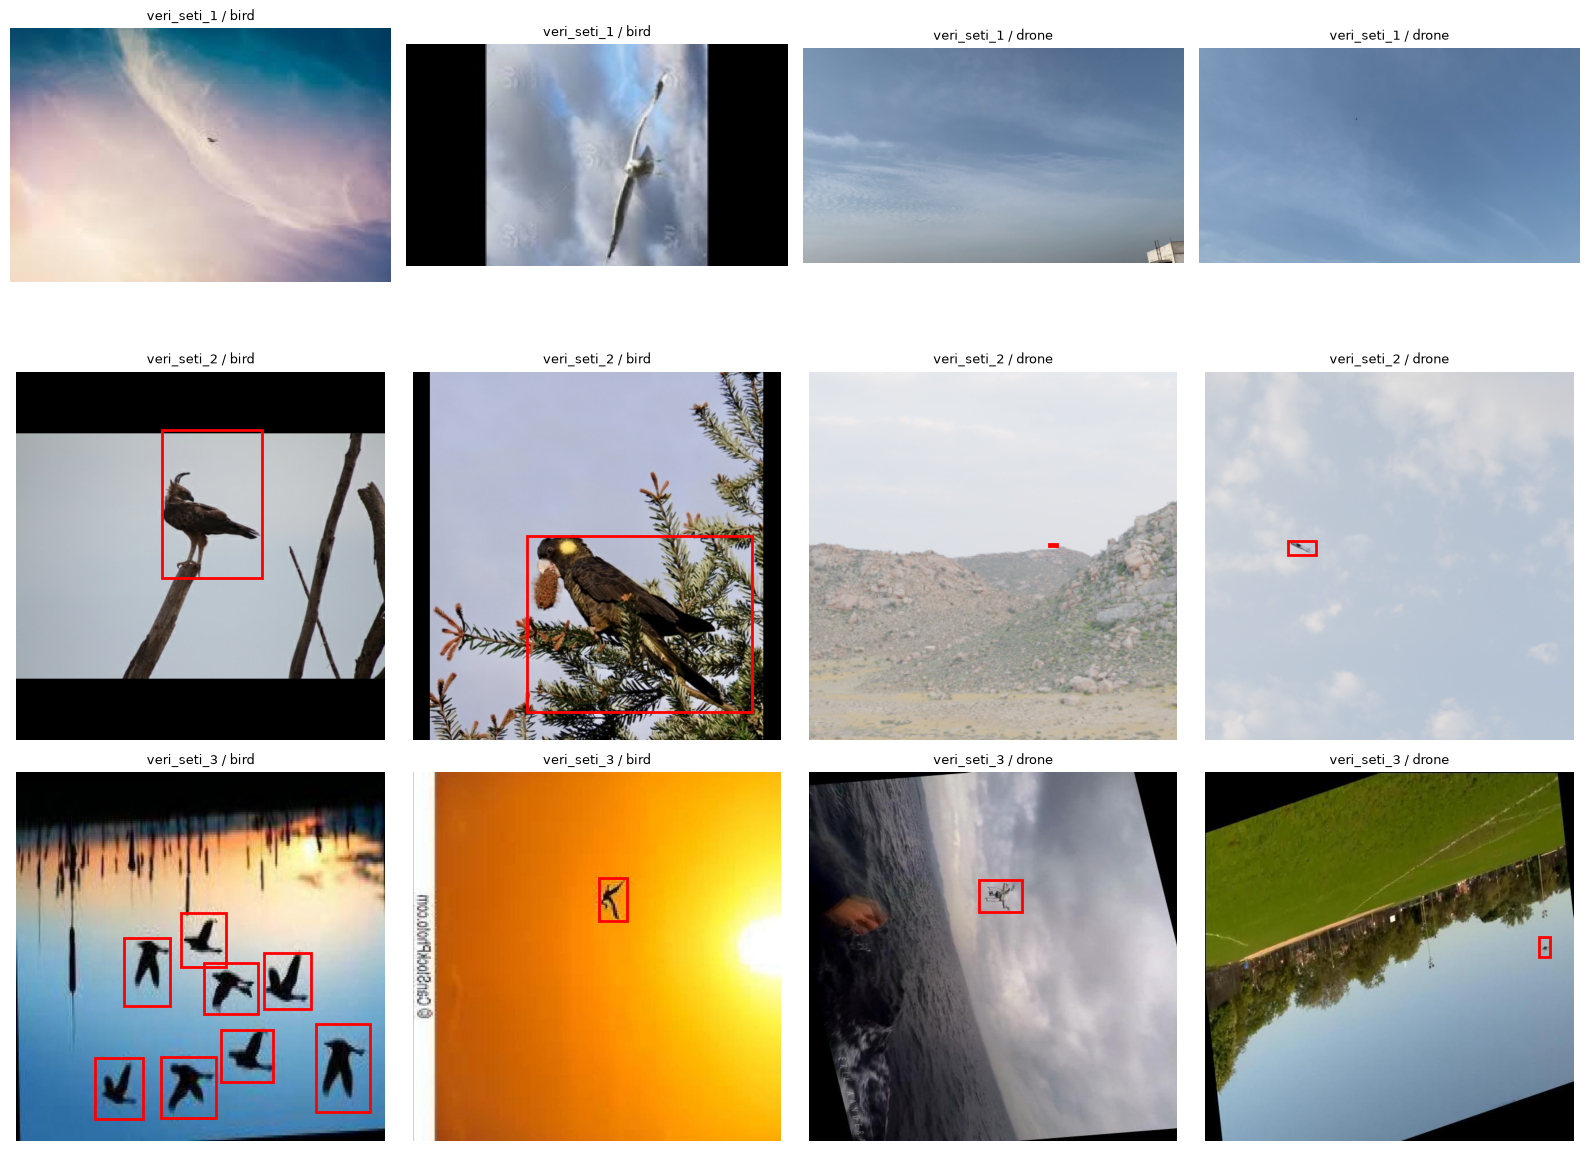

Görsel 2 (Sınıf Dağılımı) oluşturuldu ve kaydedildi.


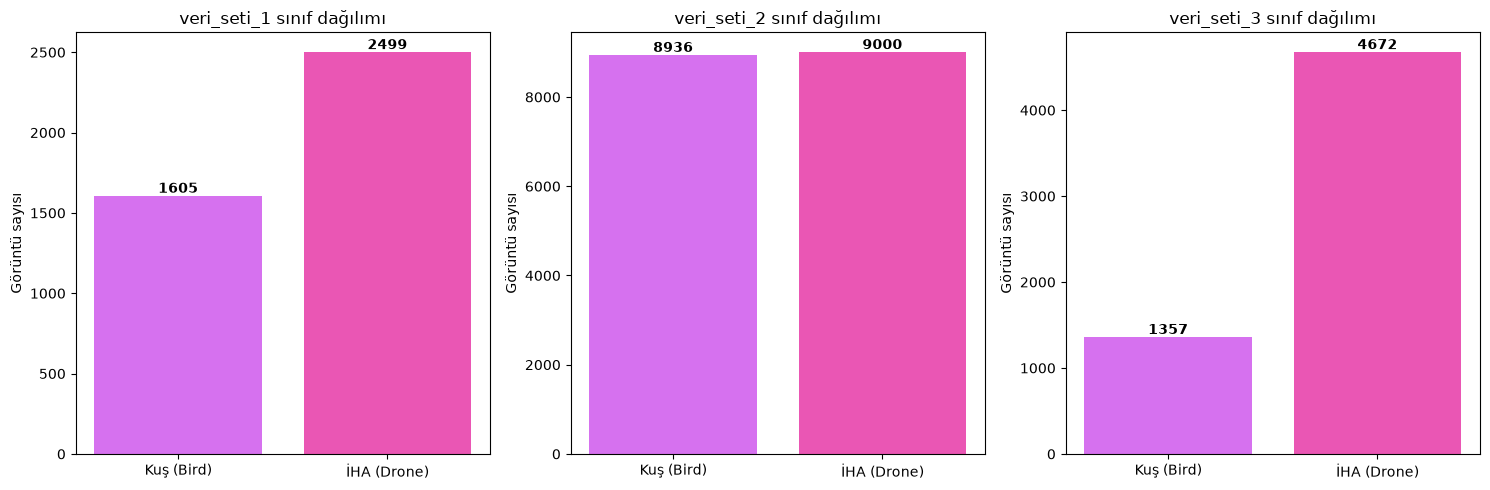

Görsel 3 (Bölünme Dağılımı) oluşturuldu ve kaydedildi.


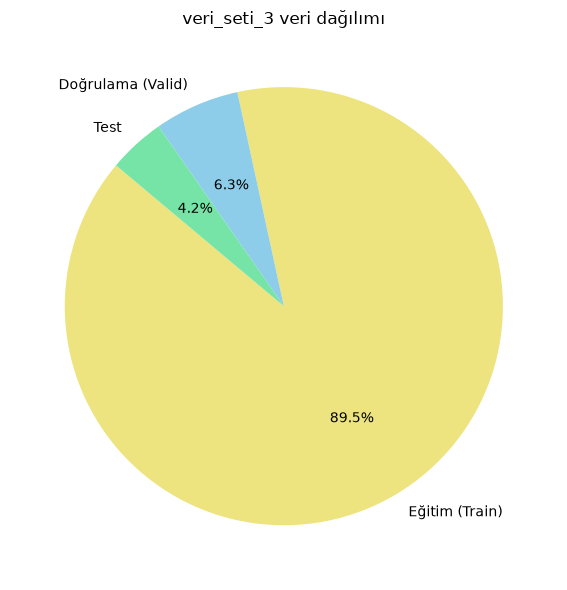

In [35]:
# GÖRSELLEŞTİRME 
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Görsellerin kaydedileceği klasör
os.makedirs("../rapor_gorselleri", exist_ok=True)

# VERİ SETLERİNDEN ÖRNEK
plt.figure(figsize=(16, 12))
satir_no = 0
for isim in sinif_resimleri:
    sutun_no = 0
    for sinif in ["bird", "drone"]:
        liste = sinif_resimleri[isim][sinif]
        secim = random.sample(liste, min(2, len(liste)))
        for resim in secim:
            plt.subplot(3, 4, satir_no * 4 + sutun_no + 1)
            img = Image.open(resim).convert("RGB")
            plt.imshow(img)
            plt.title(f"{isim} / {sinif}", fontsize=9)
            plt.axis("off")
            # etiket varsa kutuyu çiz (kırmızı)
            if etiket_yolu[resim] is not None:
                for sinif_no, x, y, w, h in kutulari_oku(etiket_yolu[resim]):
                    gen, yuk = img.size
                    sol = (x - w / 2) * gen
                    ust = (y - h / 2) * yuk
                    plt.gca().add_patch(Rectangle((sol, ust), w * gen, h * yuk, fill=False, edgecolor="red", linewidth=2))
            sutun_no += 1
    satir_no += 1

plt.tight_layout()
plt.savefig("../rapor_gorselleri/gorsel1_ornek_resimler.png", dpi=150)
print("Görsel 1 (Örnek Resimler) oluşturuldu ve kaydedildi.")
plt.show()

# SINIF DAĞILIMI 
plt.figure(figsize=(5 * len(sonuc), 5))
sira = 1
for isim in sonuc:
    plt.subplot(1, len(sonuc), sira)
    siniflar = ["Kuş (Bird)", "İHA (Drone)"]
    sayilar = [sonuc[isim]["bird"], sonuc[isim]["drone"]]
    cubuklar = plt.bar(siniflar, sayilar, color=["#D15FEEE2", "#EA56B4"])
    plt.title(f"{isim} sınıf dağılımı")
    plt.ylabel("Görüntü sayısı")
    for cubuk in cubuklar:
        yukseklik = cubuk.get_height()
        plt.text(cubuk.get_x() + cubuk.get_width() / 2, yukseklik, str(int(yukseklik)), ha="center", va="bottom", fontweight="bold")
    sira += 1

plt.tight_layout()
plt.savefig("../rapor_gorselleri/gorsel2_sinif_dagilimi.png", dpi=150)
print("Görsel 2 (Sınıf Dağılımı) oluşturuldu ve kaydedildi.")
plt.show()

# EĞİTİM / DOĞRULAMA / TEST DAĞILIMI 
bolunmus = []
for isim in sonuc:
    if sonuc[isim]["egitim"] + sonuc[isim]["dogrulama"] + sonuc[isim]["test"] > 0:
        bolunmus.append(isim)

if len(bolunmus) == 0:
    print("Hiçbir veri seti train/valid/test olarak bölünmemiş.")
else:
    plt.figure(figsize=(6 * len(bolunmus), 6))
    sira = 1
    for isim in bolunmus:
        plt.subplot(1, len(bolunmus), sira)
        sayilar = [sonuc[isim]["egitim"], sonuc[isim]["dogrulama"], sonuc[isim]["test"]]
        plt.pie(sayilar, labels=["Eğitim (Train)", "Doğrulama (Valid)", "Test"], autopct="%1.1f%%",
                colors=["#EDE47F", "#8ECDEA", "#76E3A7"], startangle=140)
        plt.title(f"{isim} veri dağılımı")
        sira += 1
    plt.tight_layout()
    plt.savefig("../rapor_gorselleri/gorsel3_egitim_test_dagilimi.png", dpi=150)
    print("Görsel 3 (Bölünme Dağılımı) oluşturuldu ve kaydedildi.")
    plt.show()